# Validate spectra (buoy vs reconstruction)

Compare **observed buoy spectra** to reconstructed metamodel spectra:

- **Buoy** — processed NetCDF (`Efth` on native freq/dir grid)
- **Bulk reconstruct** — `mm.reconstruct(..., spectral=False)` + `save_spectra`
- **Partition reconstruct** — `mm.reconstruct(..., spectral=True)` (WHACS partitions 0–3 summed)

Every figure below is the same **3 columns, 1 row** layout — buoy, bulk, spectral,
always in that order, left to right — for one "moment" (one random timestep, one
monthly mean, one seasonal mean). However many moments get plotted, each one is its
own side-by-side comparison, so the same thing is always directly comparable instead
of scattered across separate per-source figures (`utils.viz.spectra_plots`;
wavespectra's own `.spec.plot()` can't target a shared subplot axis, so each panel is
rendered independently and composed as images — see that module's docstring).

**Prerequisites:** spectra caches under `tmp/reconstruct/` for the same `period`,
`sites`, and `mda_n` (`save_spectra: true` in the case JSON).

In [1]:
import numpy as np
import xarray as xr
from IPython.display import display
from utils.config import resolve
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs
from utils.viz.spectra_plots import plot_spectrum_comparison

## Configuration

In [ ]:
period = "2010"
offshore_name = "WHACS"
mda_n = 450
pca_variance = 0.99
wl = 0.0
goals = None  # all goals

buoy_instruments = ["buoy_BatemansBay_Buoy"]  # instrument_id values from notebook 03
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]
site_id = sites[0]

# Processed observation NetCDF per SnapWave site id
buoy_raw_files = {
    obs.snapwave_site_id("buoy_BatemansBay_Buoy"): (
        "inputs/Observations/processed/spectra/BatemansBay_Buoy.nc"
    ),
}

n_random = 12
random_seed = 42

# Reconstruct spectra for every buoy that actually *has* raw spectral
# observations (only 3 of the 35 do — the rest are bulk-only Spotter
# deployments with no Efth to compare against, see notebook 00's spectral
# processing) rather than just `site_id`. GP prediction cost is dominated by
# how many *goals* the requested sites touch, not by how many end up kept
# (mm.predict() always predicts every PCA component for a goal and subsets
# to the requested sites afterward) — so this costs about the same as
# reconstructing site_id alone, and leaves the other 2 buoys cached too,
# instead of quietly repaying the same per-goal cost the next time this
# notebook analyses a different one of them. Going wider still, to all 35
# buoys, would multiply the spectra cache size (~2-3 GB for these 3 at a
# full year) for sites with no observed spectrum to ever compare it to.
spectral_buoy_dir = resolve("inputs/Observations/processed/spectra")
spectral_buoy_site_ids = sorted(
    obs.snapwave_site_id(p.stem) for p in spectral_buoy_dir.glob("*.nc")
)

recon_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=goals,
    wl=wl,
    site_ids=spectral_buoy_site_ids,
    pca_variance=pca_variance,
)

print("Observations JSON:", obs.geojson_path())
print(f"period   : {period}")
print(f"site     : {site_id}")
print(f"spectral buoys (reconstructed together): {spectral_buoy_site_ids}")

## 1 · Load spectra

In [ ]:
buoy_raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)
spec_var = "Efth" if "Efth" in buoy_raw else "efth"
buoy_efth = buoy_raw[spec_var]

# Reconstruct once for all 3 spectral buoys together (see recon_kw above) so
# this cache is reusable for Sydney/ByronBay/BatemansBay alike. Cheap if
# already cached from a previous run of this cell; otherwise budget a few
# minutes the first time (one mm.reconstruct() per mode). Both modes need
# save_spectra=True — "bulk" (spectral=False) still writes its own efth
# companion (single WHACS partition -1), same as the partitioned mode.
# reconstruct() takes `sites=`, not recon_kw's `site_ids=` (that one's for
# load_reconstruction_spectra below) — build its kwargs separately.
reconstruct_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=goals,
    wl=wl,
    sites=spectral_buoy_site_ids,
    pca_variance=pca_variance,
)
mm.reconstruct(period, spectral=False, save_spectra=True, **reconstruct_kw)
mm.reconstruct(period, spectral=True, save_spectra=True, **reconstruct_kw)

bulk_spec = mm.load_reconstruction_spectra(
    period, spectral=False, load=False, **recon_kw
)
part_spec = mm.load_reconstruction_spectra(
    period, spectral=True, load=False, **recon_kw
)

for label, ds in [("bulk", bulk_spec), ("partition", part_spec)]:
    if ds is None:
        raise FileNotFoundError(
            f"Missing {label} spectra cache for {period!r} — run "
            f"mm.reconstruct(..., spectral={label == 'partition'}, recompute=True) "
            "with save_spectra=true in the case JSON."
        )

bulk_efth = bulk_spec["efth"].sel(sites=site_id)
part_efth = part_spec["efth"].sel(sites=site_id)

print("Buoy :", dict(buoy_efth.sizes))
print("Bulk :", dict(bulk_efth.sizes))
print("Part :", dict(part_efth.sizes))

## 2 · Helpers

In [ ]:
def pick_random_time_index(n: int, n_time: int, seed: int) -> np.ndarray:
    """Sorted integer indices along ``time``."""
    rng = np.random.default_rng(seed)
    n_pick = min(n, n_time)
    return np.sort(rng.choice(n_time, size=n_pick, replace=False))


def monthly_mean_spectra(da: xr.DataArray) -> dict[str, xr.DataArray]:
    """One time-averaged spectrum per calendar month present, keyed ``month=N``."""
    months = sorted({int(m) for m in da["time"].dt.month.values})
    return {
        f"month={month}": da.sel(time=da.time.dt.month == month).mean(
            "time", skipna=True
        )
        for month in months
    }


def seasonal_mean_spectra(da: xr.DataArray) -> dict[str, xr.DataArray]:
    """One time-averaged spectrum per season present, keyed ``season=DJF`` etc."""
    seasons = sorted({str(s) for s in da["time"].dt.season.values})
    return {
        f"season={season}": da.sel(time=da.time.dt.season == season).mean(
            "time", skipna=True
        )
        for season in seasons
    }


PANEL_LABELS = (
    "Buoy observed",
    "Reconstruction bulk (partition -1)",
    "Reconstruction spectral (partitions 0-3)",
)
# Every panel is plotted with wavespectra's default normalised=True (each
# spectrum independently scaled 0-1 by its own peak) — the 3 sources' raw
# attrs disagree on what to call that ("Hsig of wind and swell", "Wave
# significant height partition 0", ...), so pin one consistent label rather
# than showing 3 differently-worded colorbars for the same 0-1 scale.
CBAR_KWARGS = {"label": "Normalised energy density", "shrink": 0.8, "pad": 0.08}


def show_triplet(
    buoy_da: xr.DataArray | None,
    bulk_da: xr.DataArray | None,
    part_da: xr.DataArray | None,
    title: str,
) -> None:
    """Buoy / bulk / spectral, always 3 columns in that order, for one moment.

    Any source missing for this particular moment (e.g. a month the buoy
    has no data for) is skipped rather than plotted blank, but the other
    panels still show — and still say which one they are.
    """
    specs = [
        (label, da)
        for label, da in zip(PANEL_LABELS, (buoy_da, bulk_da, part_da), strict=True)
        if da is not None
    ]
    if not specs:
        print(f"{title}: nothing to plot (missing on all 3 sources)")
        return
    missing = [
        label
        for label, da in zip(PANEL_LABELS, (buoy_da, bulk_da, part_da), strict=True)
        if da is None
    ]
    print(f"— {title} —" + (f"  (missing: {', '.join(missing)})" if missing else ""))
    display(plot_spectrum_comparison(specs, cbar_kwargs=CBAR_KWARGS))


sample_idx = pick_random_time_index(n_random, buoy_efth.sizes["time"], random_seed)
sample_buoy = buoy_efth.isel(time=sample_idx).load()
sample_bulk = bulk_efth.sel(time=buoy_efth.time.values[sample_idx]).load()
sample_part = part_efth.sel(time=buoy_efth.time.values[sample_idx]).load()

print(f"Random sample: {len(sample_idx)} timesteps (seed={random_seed})")
print("Sample times:", sample_buoy.time.values[:3], "...")

Random sample: 4 timesteps (seed=42)
Sample times: ['2010-04-03T20:00:00.000000000' '2010-07-11T15:00:00.000000000'
 '2010-09-13T08:00:00.000000000'] ...


## 3 · Random timesteps

Independent draws on a shared hourly time axis (buoy and reconstruction times match).
One 3-column comparison per timestep — increase `n_random` above for more, the layout
doesn't change.

— buoy_ByronBay_Buoy — 2010-04-03T20 —


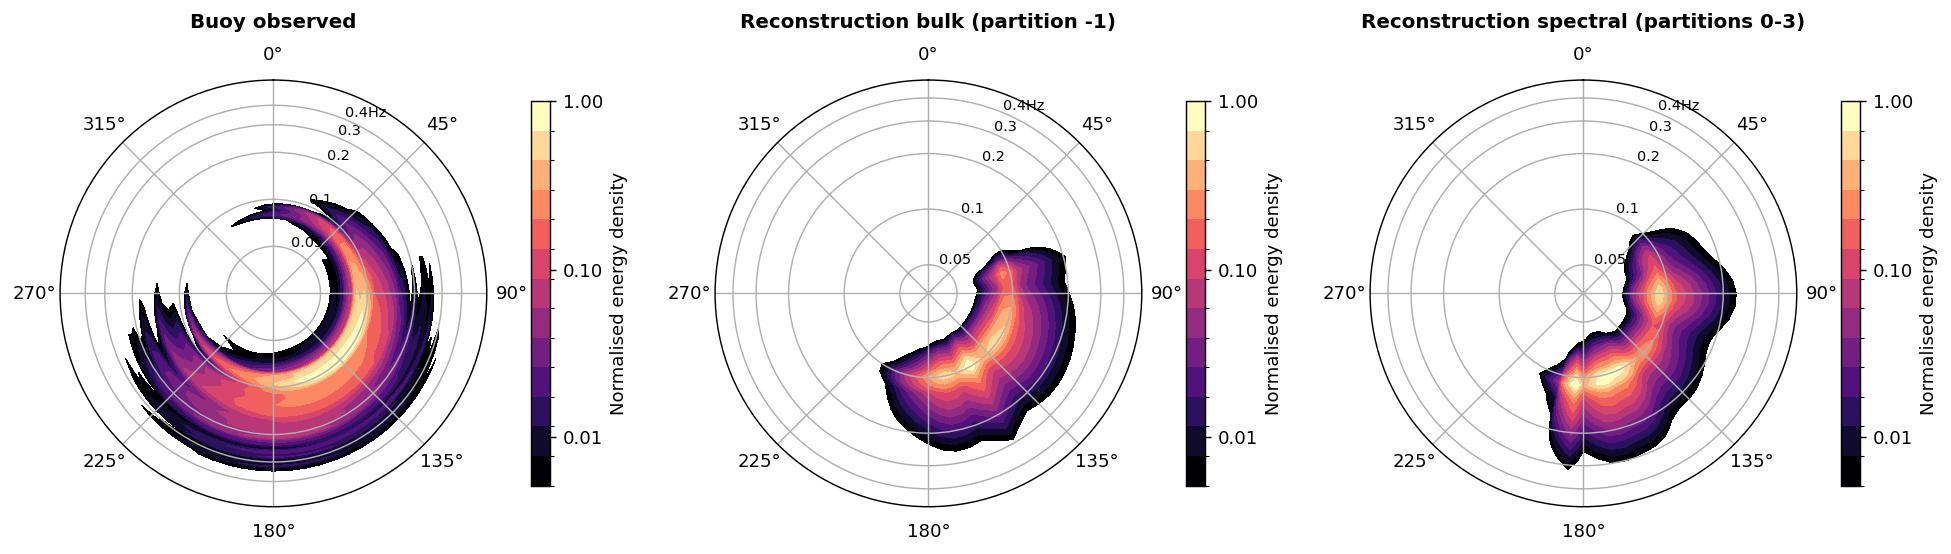

— buoy_ByronBay_Buoy — 2010-07-11T15 —


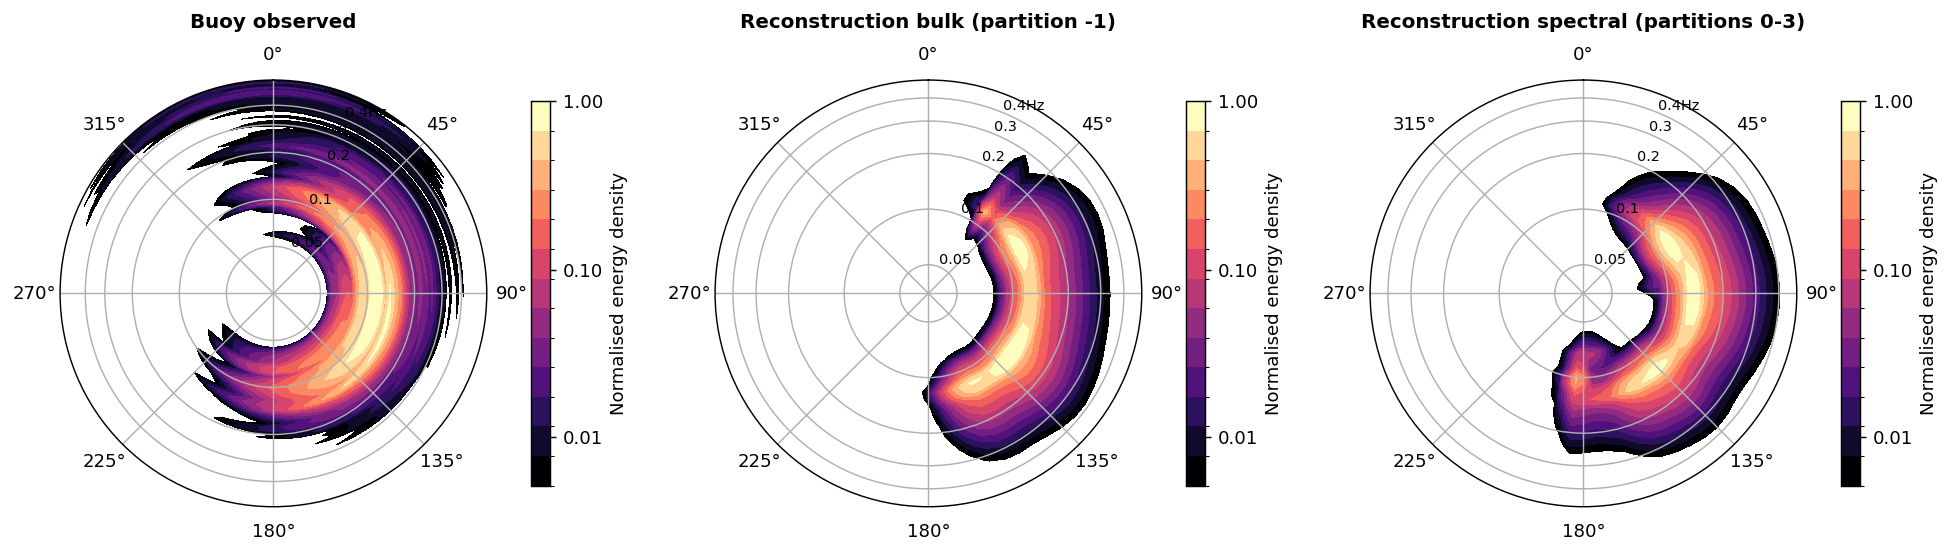

— buoy_ByronBay_Buoy — 2010-09-13T08 —


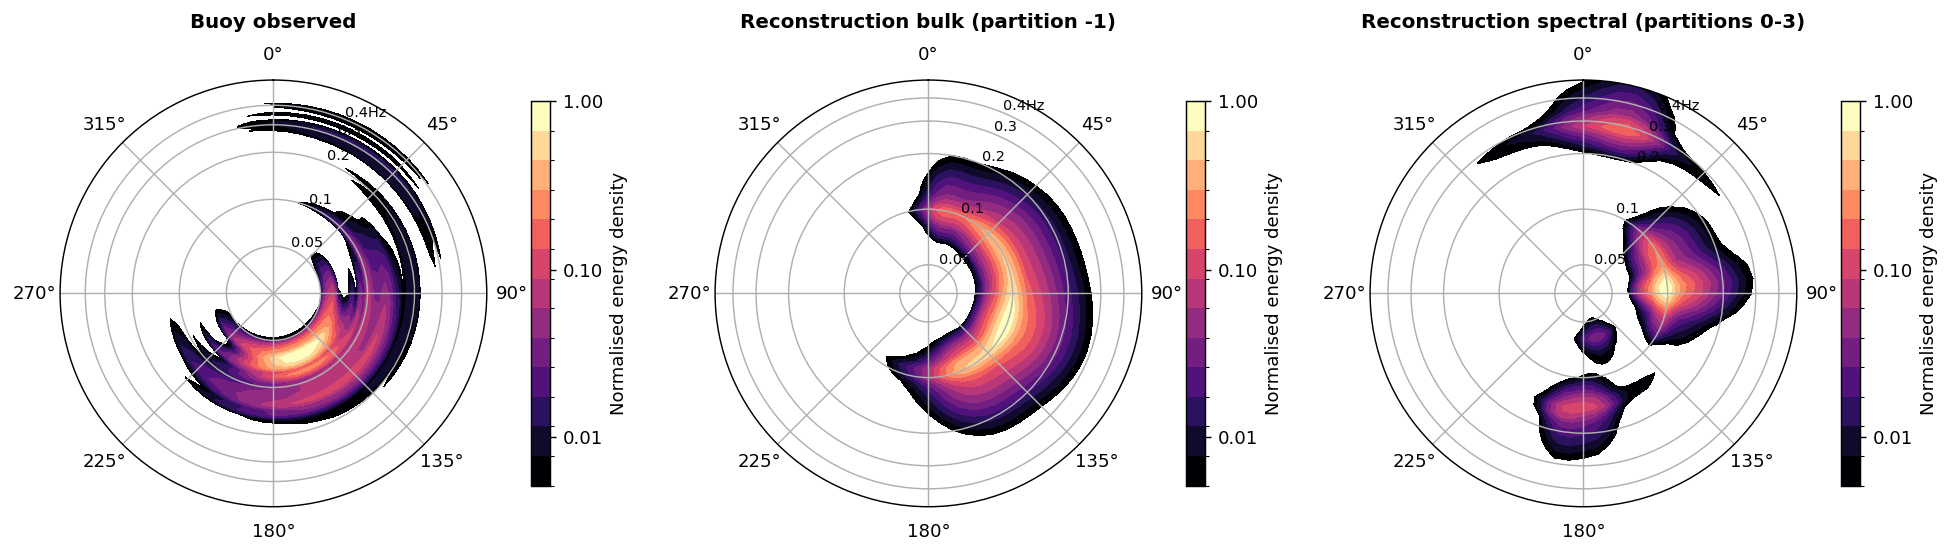

— buoy_ByronBay_Buoy — 2010-10-16T12 —


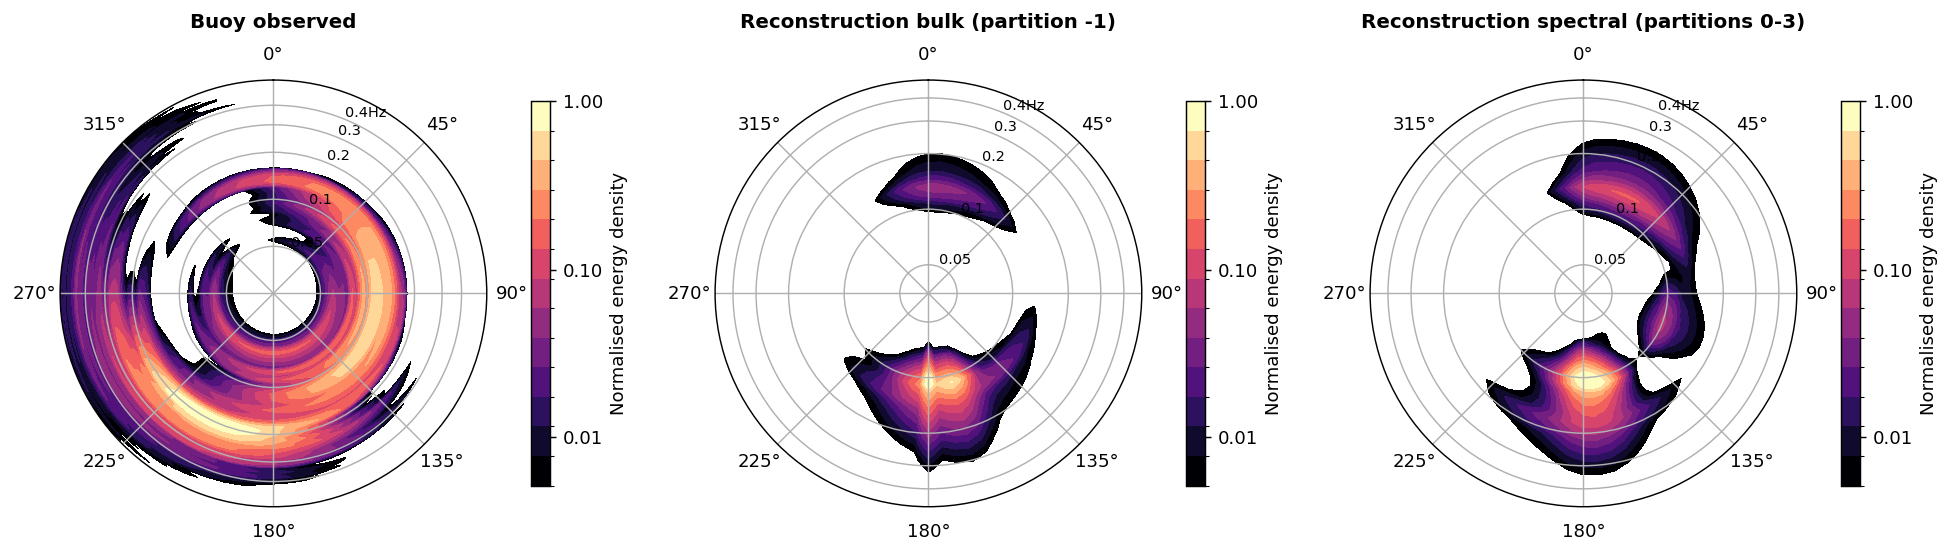

In [ ]:
for i in range(sample_buoy.sizes["time"]):
    t = sample_buoy.time.values[i]
    show_triplet(
        sample_buoy.isel(time=i),
        sample_bulk.isel(time=i),
        sample_part.isel(time=i),
        f"{site_id} — {np.datetime_as_string(t, unit='h')}",
    )

## 4 · Monthly mean spectra

— buoy_ByronBay_Buoy — 2010 — month=1 —


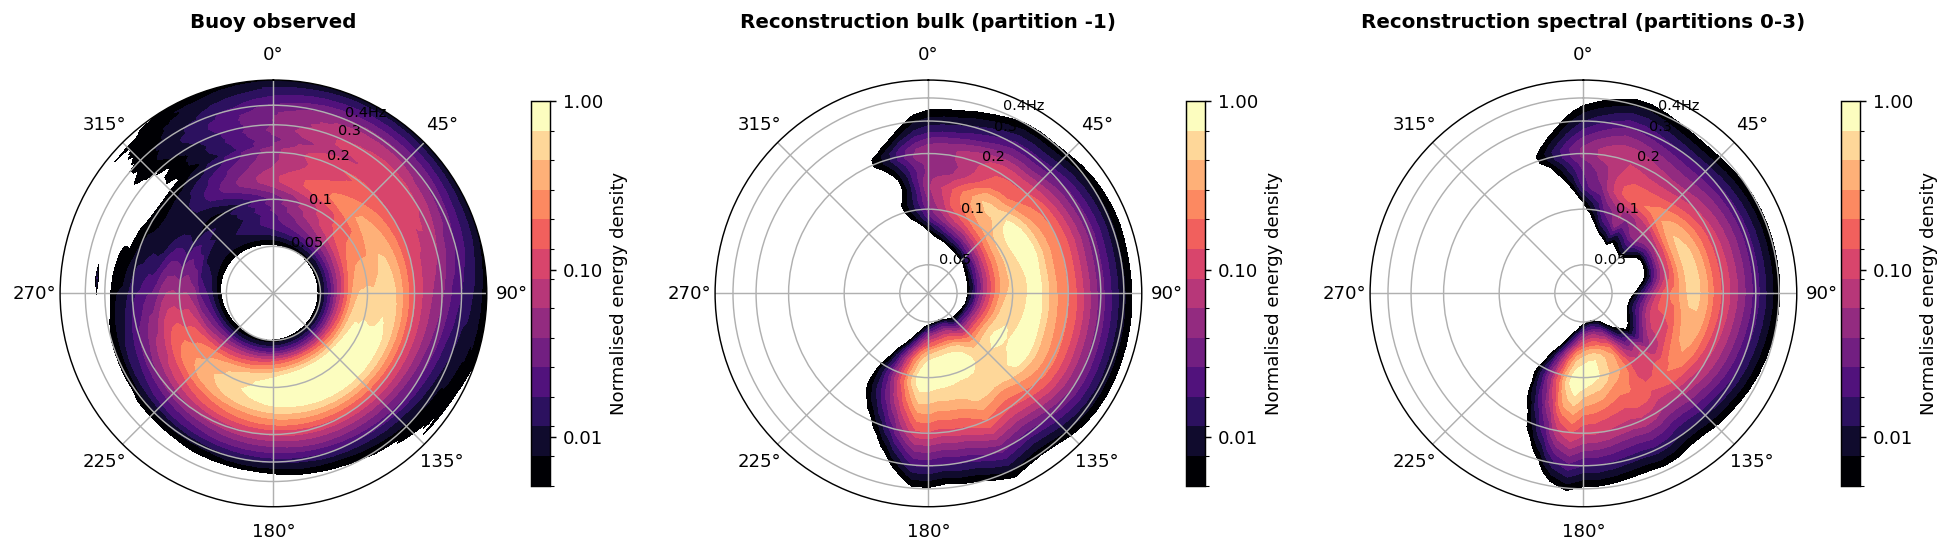

— buoy_ByronBay_Buoy — 2010 — month=3 —


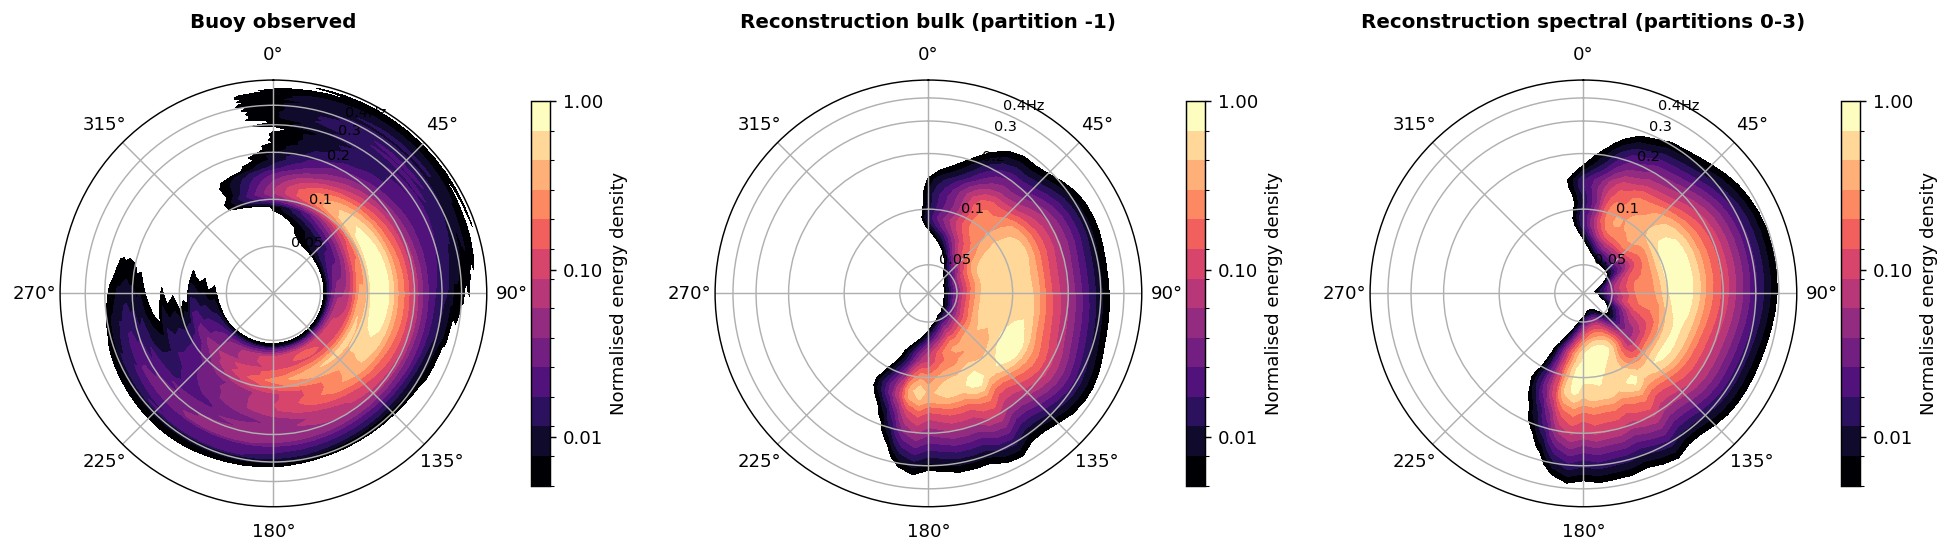

— buoy_ByronBay_Buoy — 2010 — month=4 —


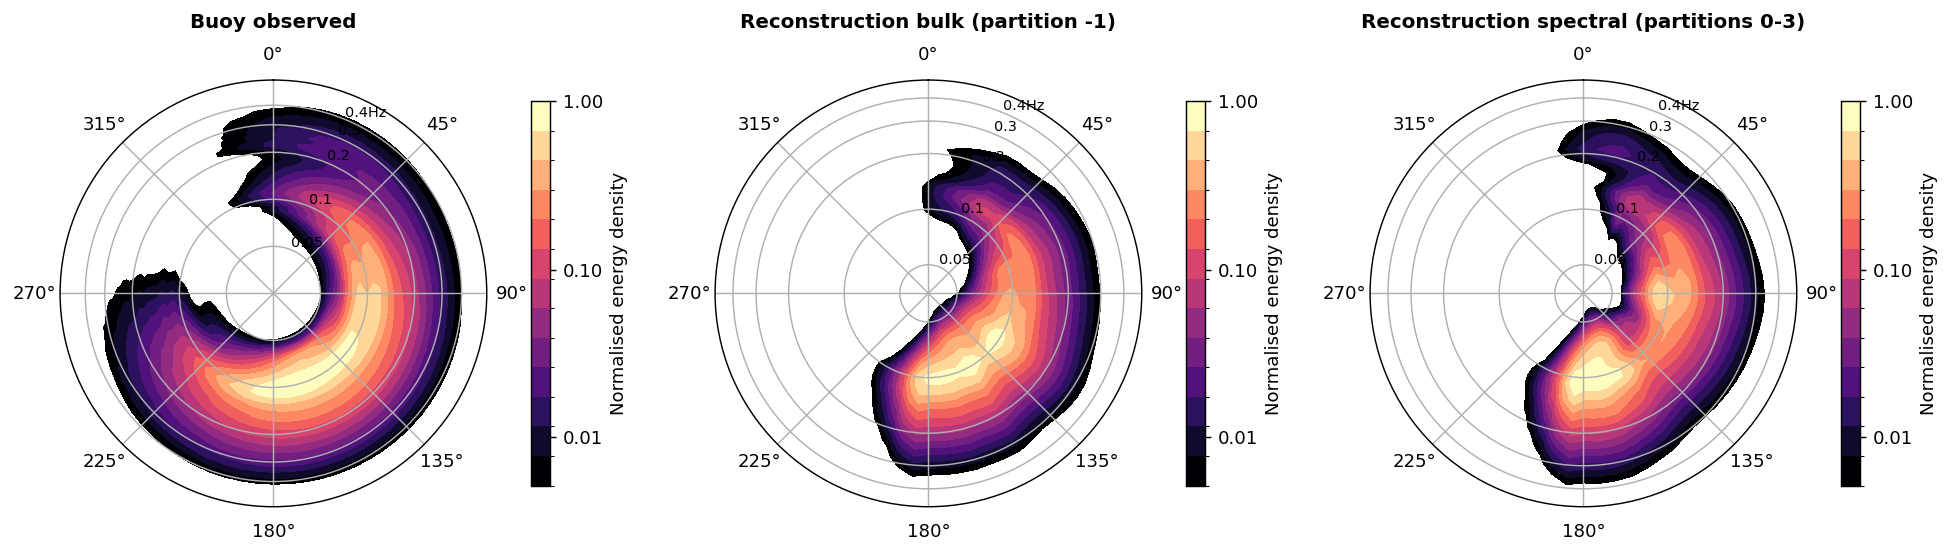

— buoy_ByronBay_Buoy — 2010 — month=5 —


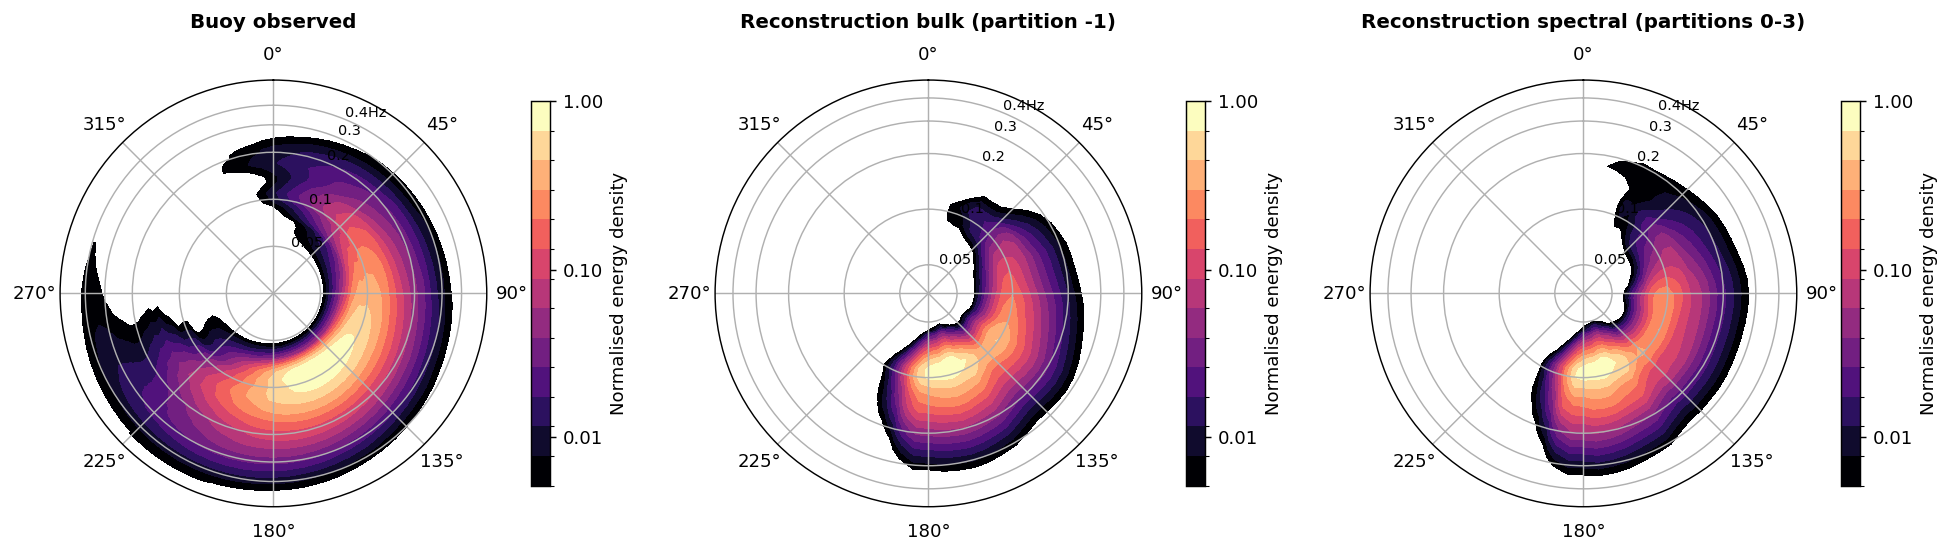

— buoy_ByronBay_Buoy — 2010 — month=6 —


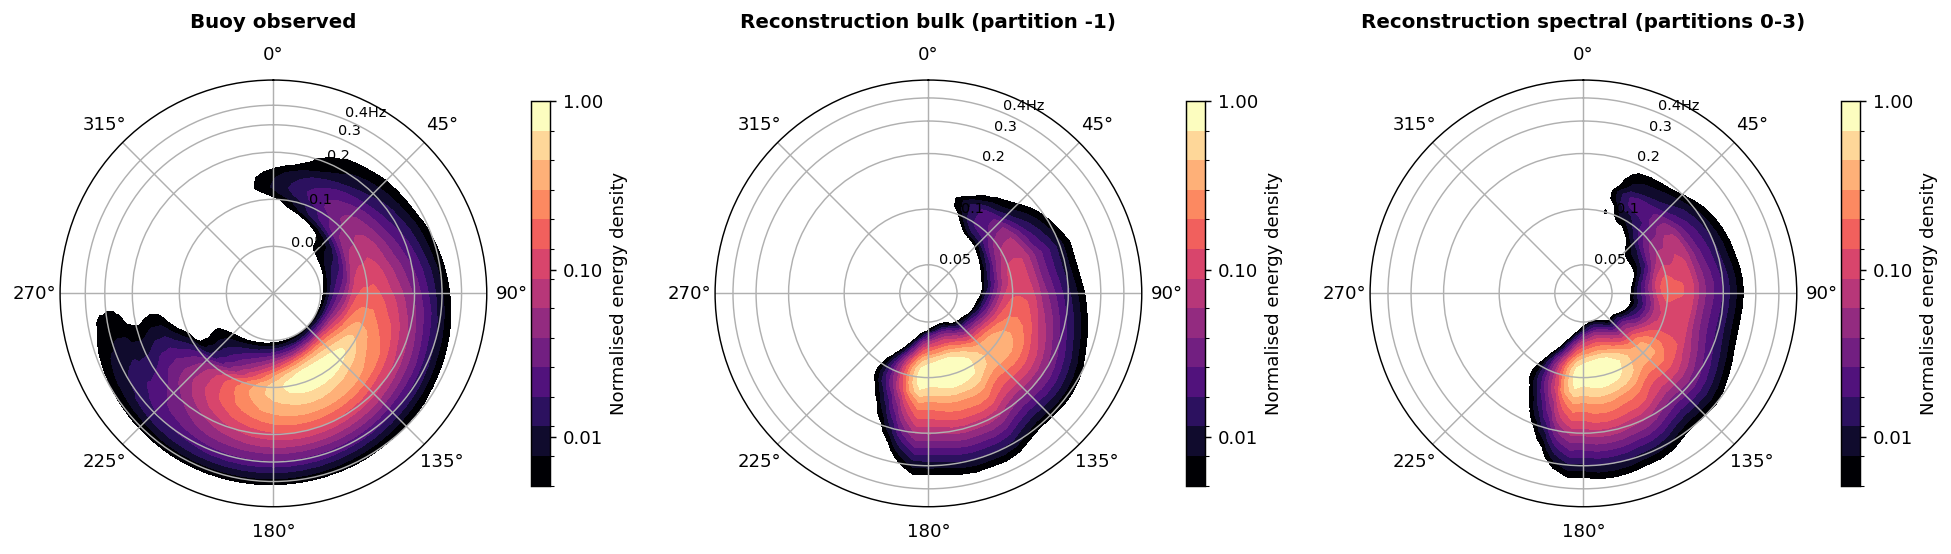

— buoy_ByronBay_Buoy — 2010 — month=7 —


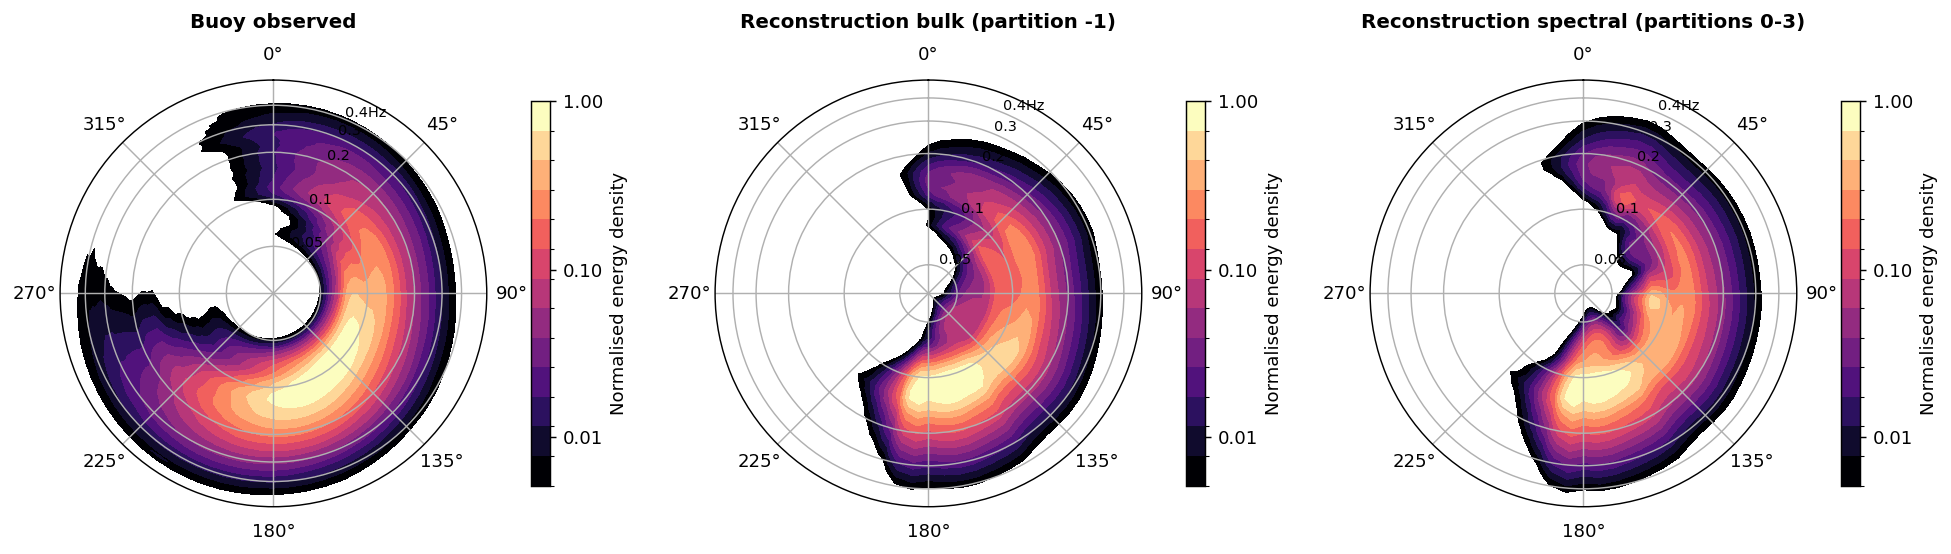

— buoy_ByronBay_Buoy — 2010 — month=8 —


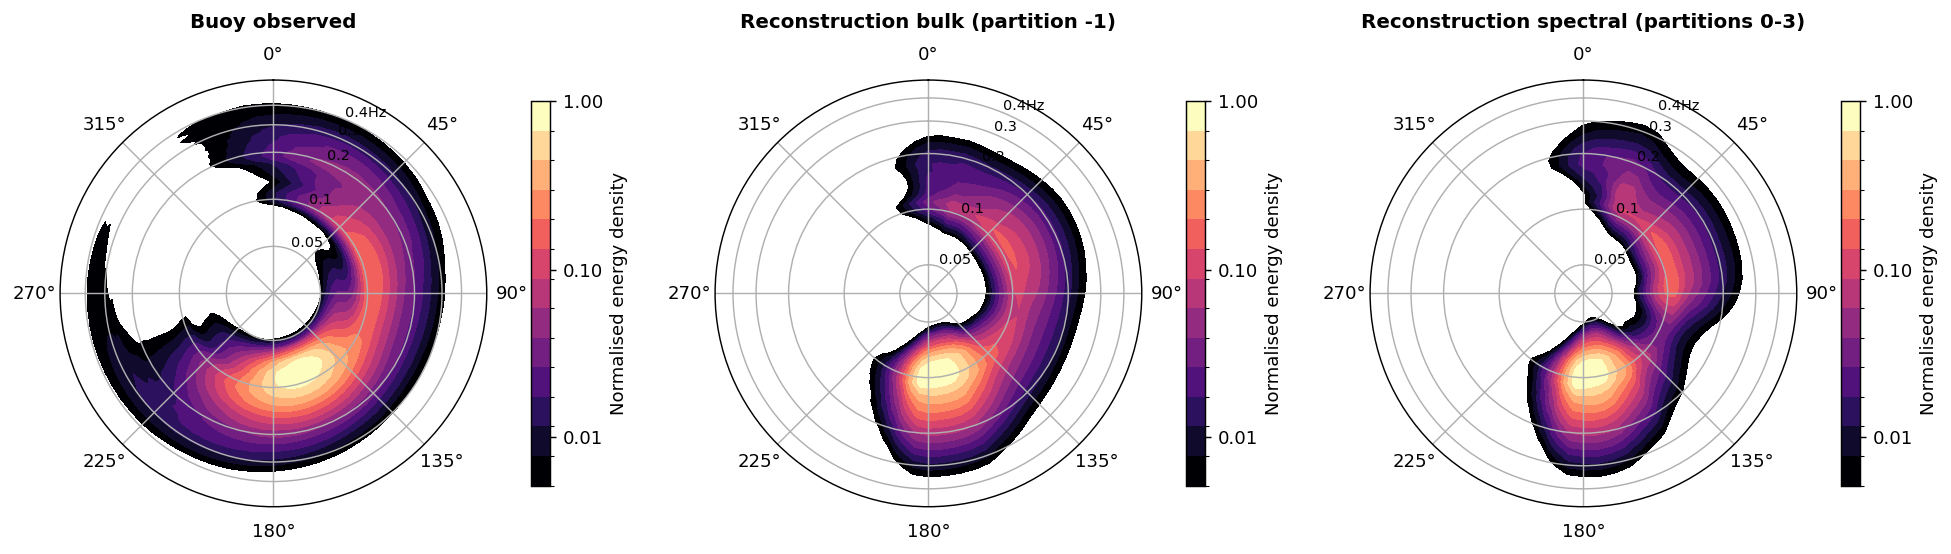

— buoy_ByronBay_Buoy — 2010 — month=9 —


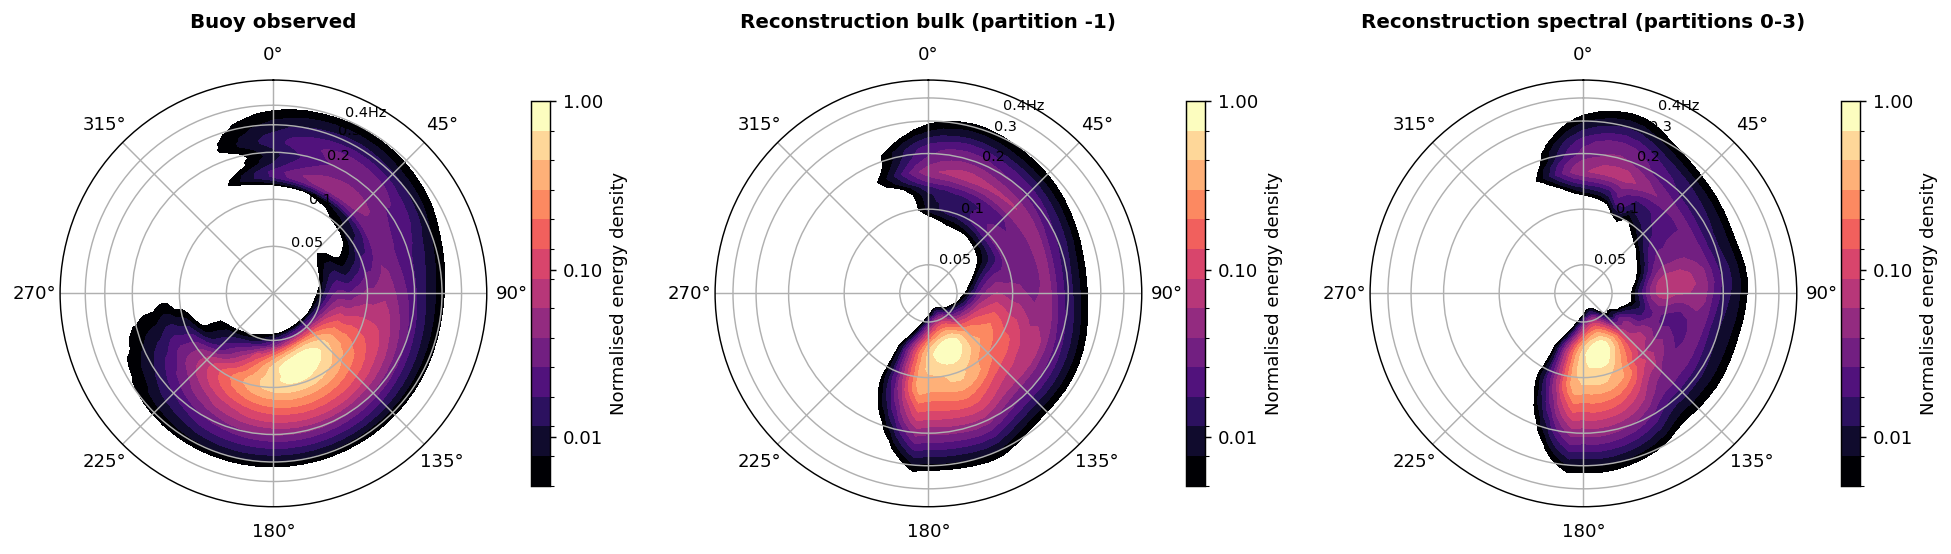

— buoy_ByronBay_Buoy — 2010 — month=10 —


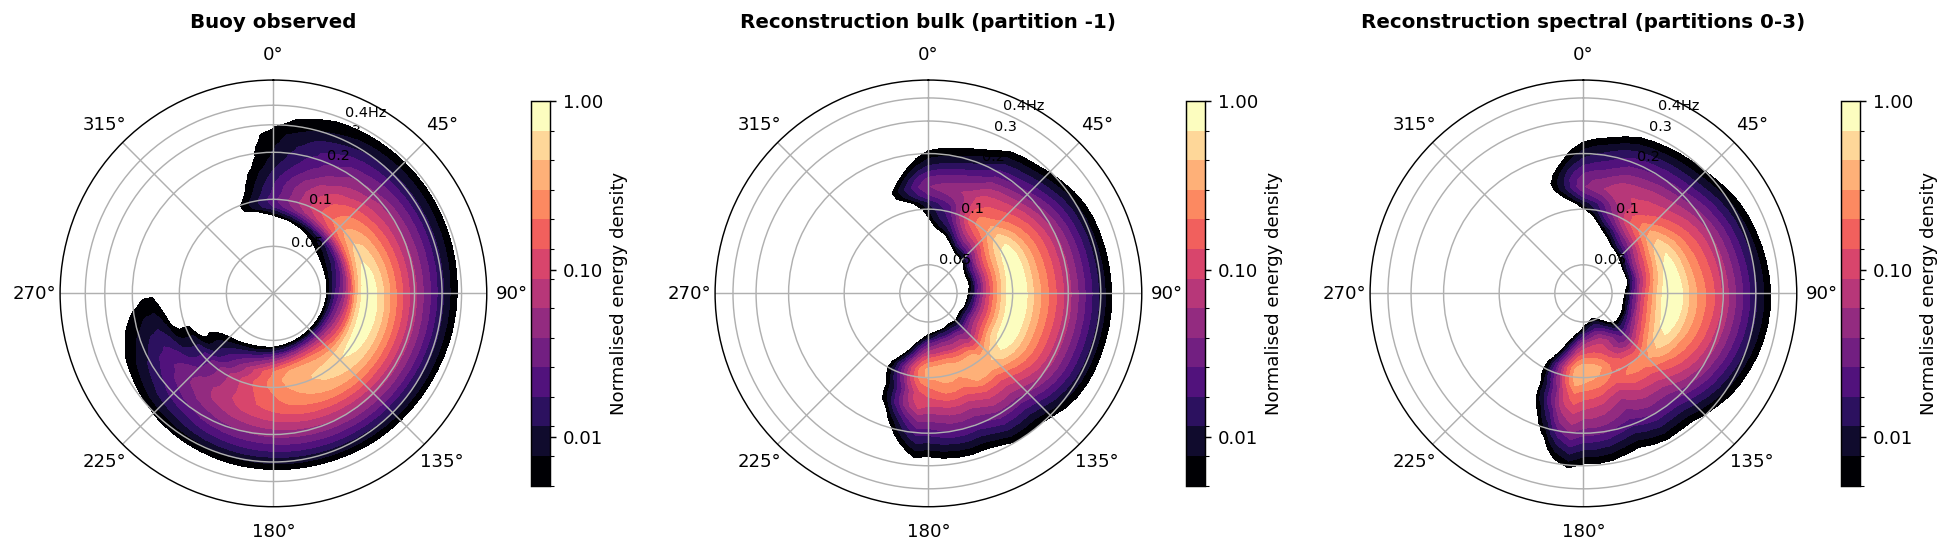

— buoy_ByronBay_Buoy — 2010 — month=11 —


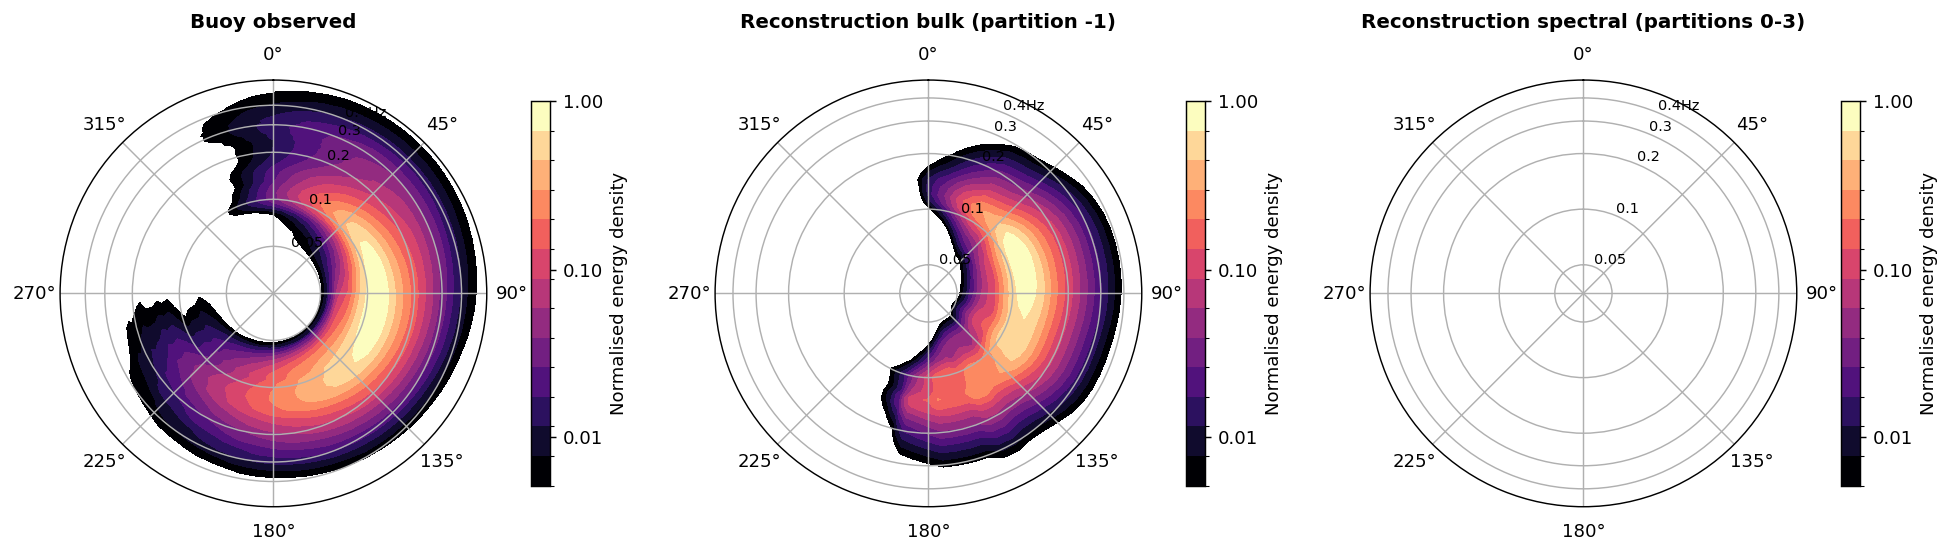

— buoy_ByronBay_Buoy — 2010 — month=12 —


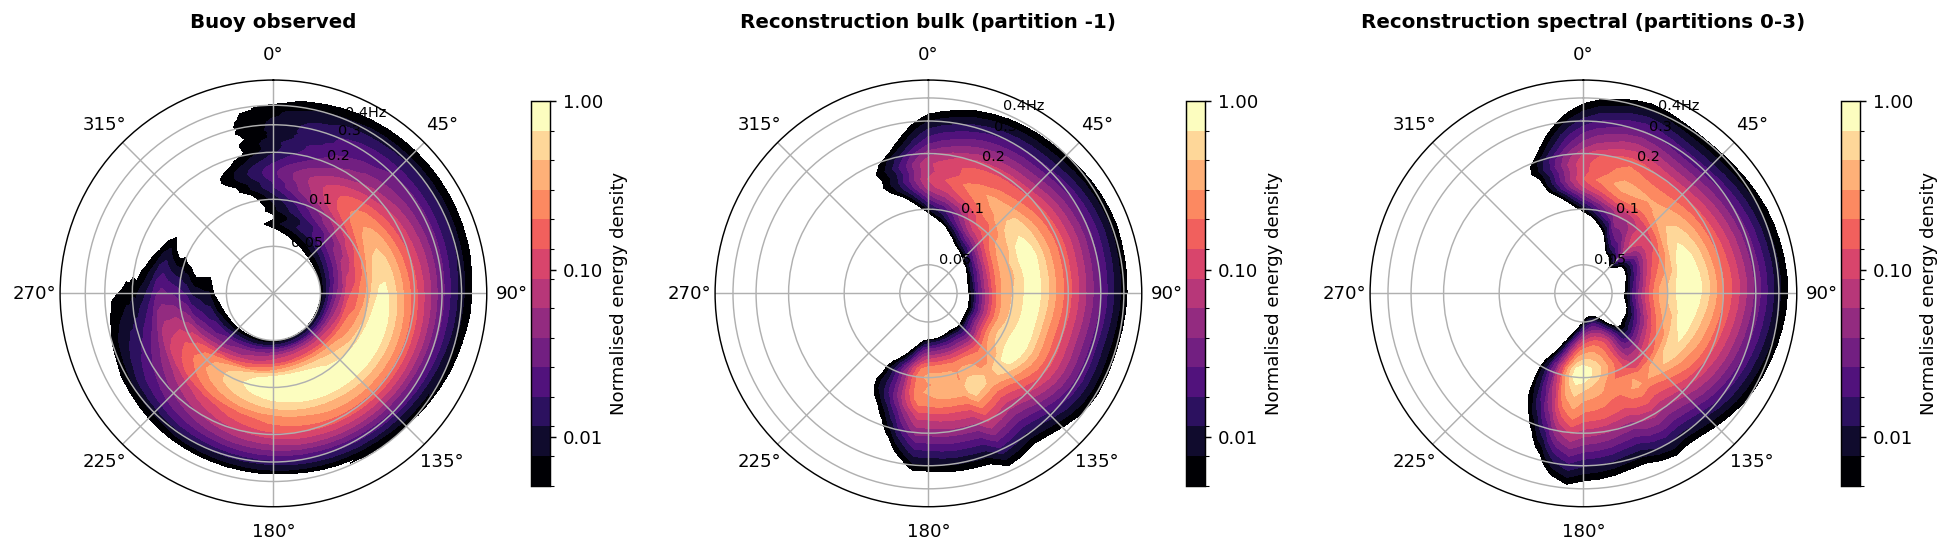

In [ ]:
buoy_monthly = monthly_mean_spectra(buoy_efth.load())
bulk_monthly = monthly_mean_spectra(bulk_efth.load())
part_monthly = monthly_mean_spectra(part_efth.load())

# Buoy coverage is the limiting factor — walk its months, not the (always
# fully hourly) reconstruction's, and skip a source that has none for it.
for key in buoy_monthly:
    show_triplet(
        buoy_monthly[key],
        bulk_monthly.get(key),
        part_monthly.get(key),
        f"{site_id} — {period} — {key}",
    )

## 5 · Seasonal mean spectra

Meteorological seasons (`DJF`, `MAM`, …). For a single calendar month there is
typically one season in the sample.

— buoy_ByronBay_Buoy — 2010 — season=DJF —


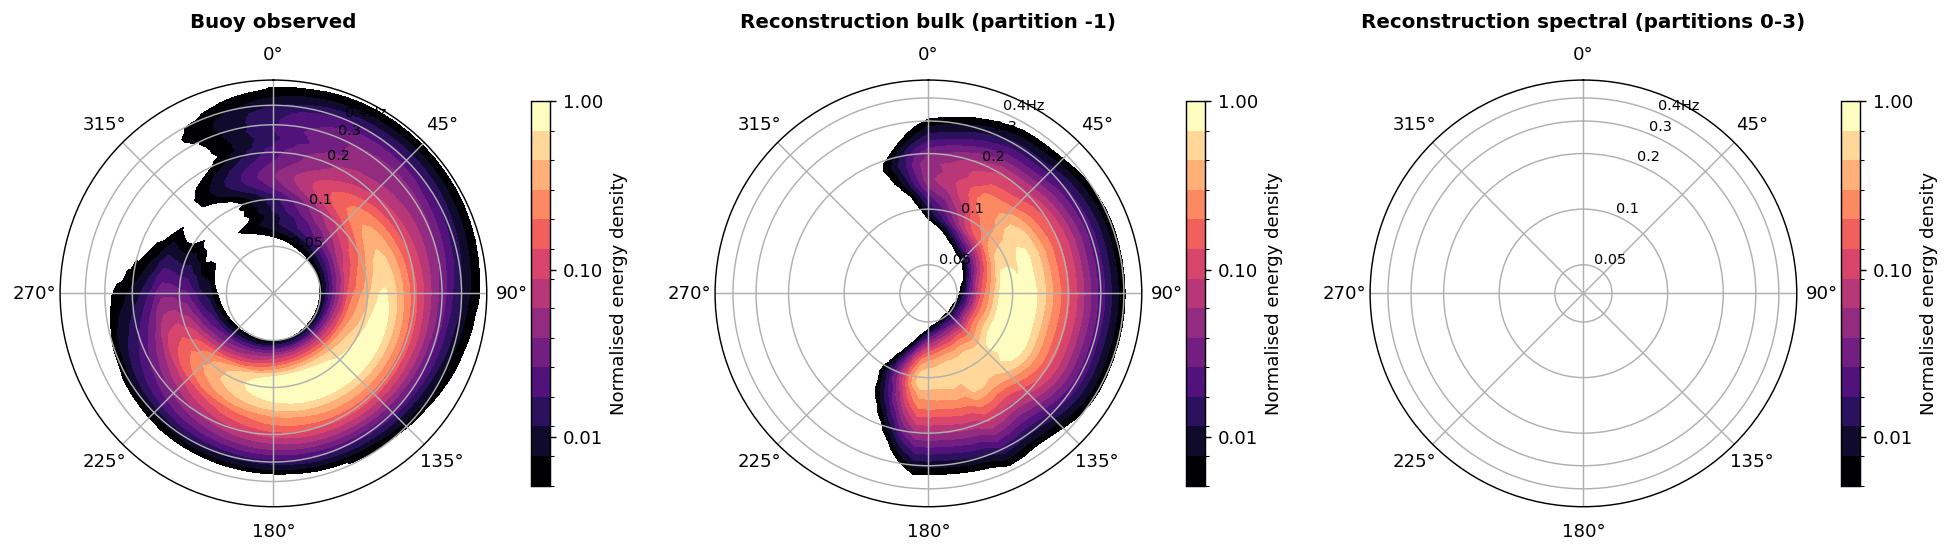

— buoy_ByronBay_Buoy — 2010 — season=JJA —


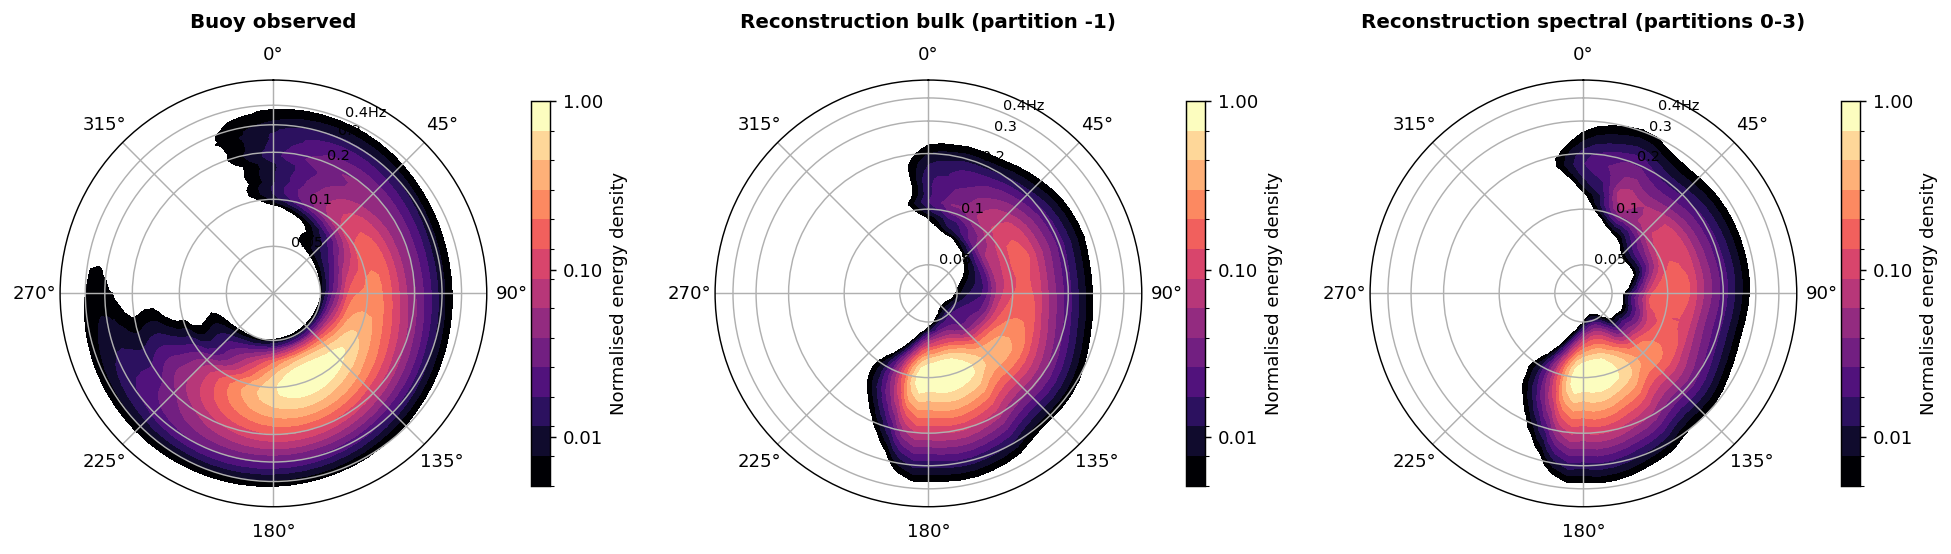

— buoy_ByronBay_Buoy — 2010 — season=MAM —


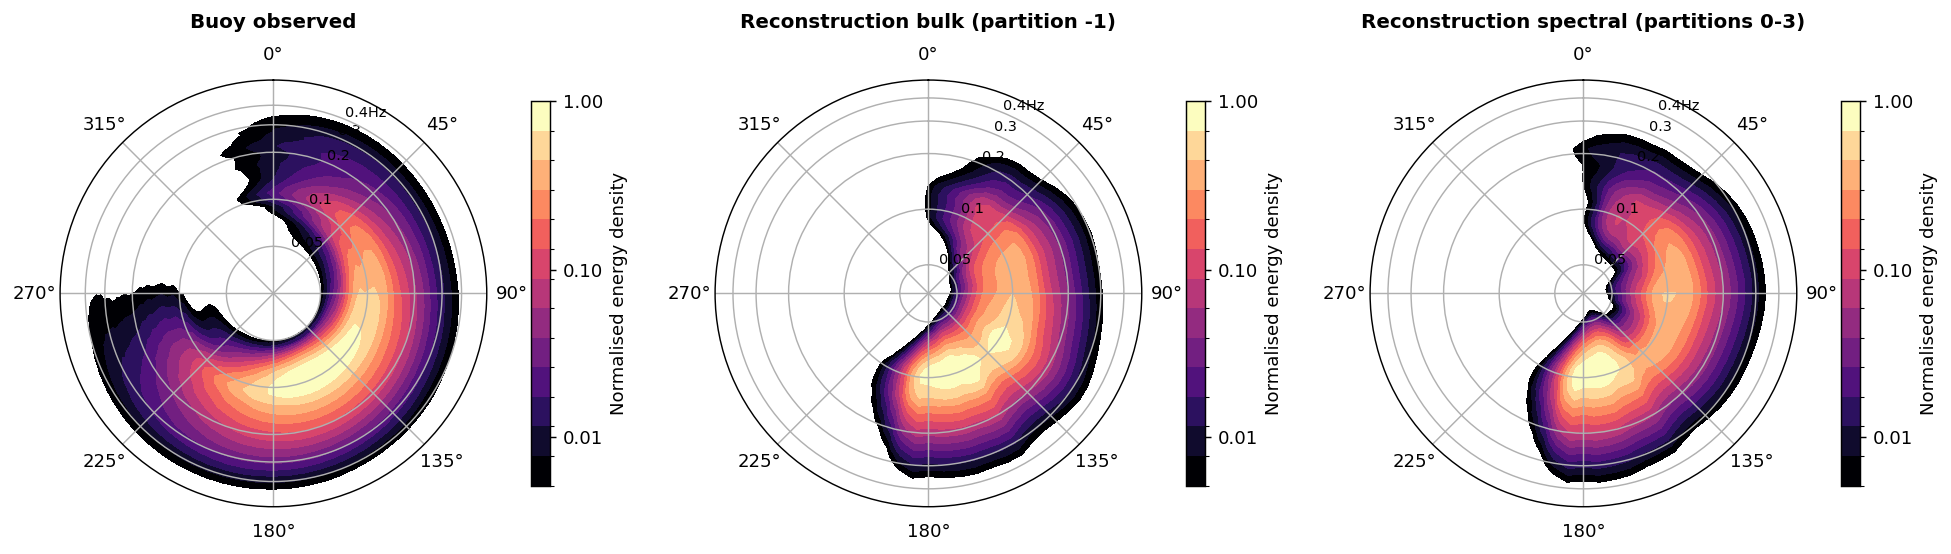

— buoy_ByronBay_Buoy — 2010 — season=SON —


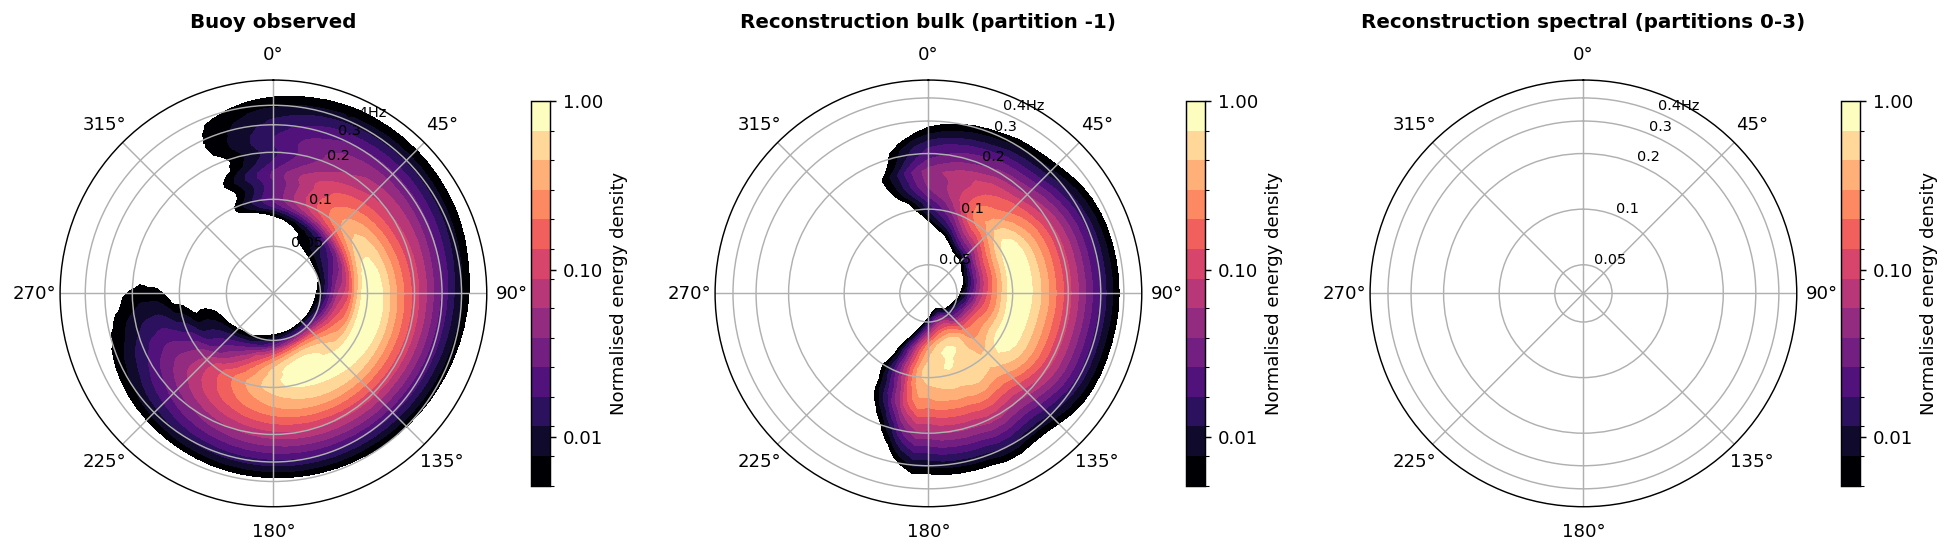

In [ ]:
buoy_seasonal = seasonal_mean_spectra(buoy_efth)
bulk_seasonal = seasonal_mean_spectra(bulk_efth)
part_seasonal = seasonal_mean_spectra(part_efth)

for key in buoy_seasonal:
    show_triplet(
        buoy_seasonal[key],
        bulk_seasonal.get(key),
        part_seasonal.get(key),
        f"{site_id} — {period} — {key}",
    )